WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.0386667561333211. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step at 0.0 ms — 0 underactive neurons
Pruned 380 synapses at t=0 ms
Plasticity step at 1000.0 ms — 15 underactive neurons
Plasticity step at 2000.0 ms — 0 underactive neurons
Pruned 226 synapses at t=2500 ms
Plasticity step at 3000.0 ms — 0 underactive neurons
Plasticity step at 4000.0 ms — 1 underactive neurons
Plasticity step at 5000.0 ms — 3 underactive neurons
Pruned 226 synapses at t=5000 ms
Plasticity step at 6000.0 ms — 6 underactive neurons
Plasticity step at 7000.0 ms — 6 underactive neurons
Pruned 226 synapses at t=7500 ms
Plasticity step at 8000.0 ms — 7 underactive neurons
Plasticity step at 9000.0 ms — 7 underactive neurons
Plasticity step at 10000.0 ms — 7 underactive neurons
Pruned 226 synapses at t=10000 ms
Plasticity step at 11000.0 ms — 7 underactive neurons
Plasticity step at 12000.0 ms — 8 underactive neurons
Pruned

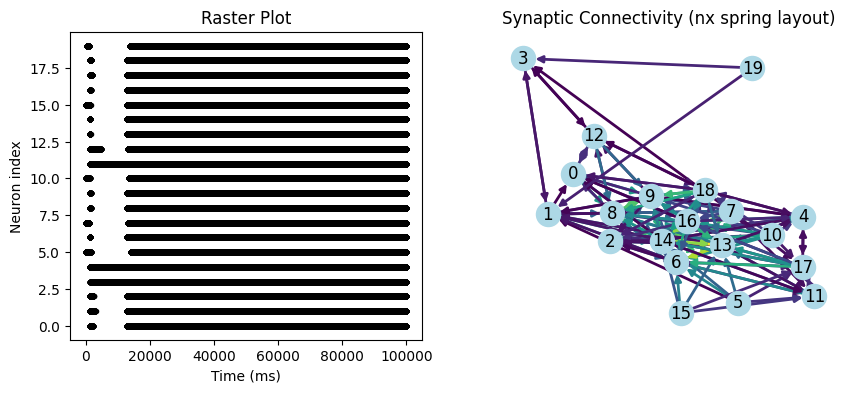

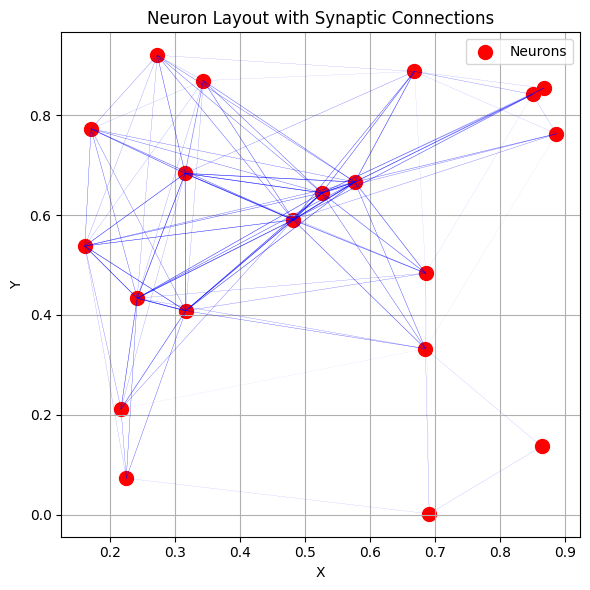

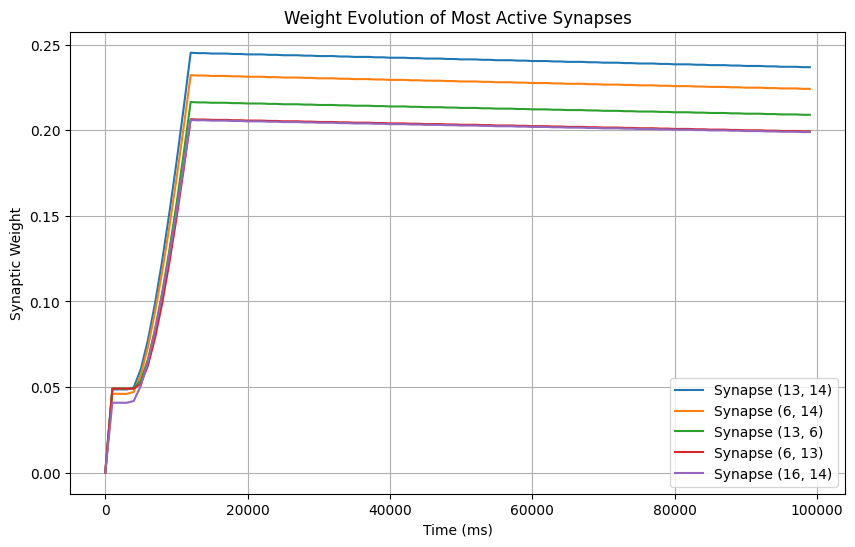

In [5]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
N_stim = 5
duration = 100*second
target_rate = 10*Hz
weight_trace = {}
times = []

neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    return np.exp(-distance**2 / (2 * sigma**2))


# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to N_stim random neurons
stim_indices = np.random.choice(N, size=N_stim, replace=False)
P_input = PoissonGroup(N_stim, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(N_stim), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w=0.0

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms — {len(underactive)} underactive neurons")

    for u in underactive:
        pos_u = neuron_positions[u]

        for pre in range(N):  # Excitatory only
            if pre == u:
                continue

            dist = np.linalg.norm(neuron_positions[pre] - pos_u)
            if dist > 0.5:
                continue

            scale = gaussian_weight(dist)
            delta = (target_rate - rates[u]) / target_rate


            S_rec.w[pre, u] = clip(S_rec.w[pre, u] + delta * 0.05 * scale, 0, 1.0)

    # overactive = np.where(rates > target_rate * 1.2)[0]  # 20% above target

    # for o in overactive:
    #     for pre in range(N):
    #         if pre == o:
    #             continue
            
    #         dist = np.linalg.norm(neuron_positions[pre] - neuron_positions[o])
    #         if dist > 0.5:
    #             continue
    #         scale = gaussian_weight(dist)
    #         delta = (rates[o] - target_rate) / target_rate
    #         S_rec.w[pre, o] = clip(S_rec.w[pre, o] - delta * 0.01 * scale, 0, 1.0)



@network_operation(dt=2500*ms)
def weight_decay():
    decay_rate = 0.001  # percent decay per second
    S_rec.w[:] *= (1 - decay_rate)
    prune_threshold = 0.0001
    S_rec.w[S_rec.w < prune_threshold] = 0
    num_pruned = np.sum(S_rec.w[:] < prune_threshold)
    print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

# @network_operation(dt=1000*ms)
# def record_weights():
#     times.append(defaultclock.t/ms)
#     for pre in range(N):
#         for post in range(N):
#             if pre == post:
#                 continue
#             try:
#                 w = S_rec.w[pre, post]
#             except IndexError:
#                 w = 0
#             if (pre, post) not in weight_trace:
#                 weight_trace[(pre, post)] = []
#             weight_trace[(pre, post)].append(w)


print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()



Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step at 1000.0 ms
Weight range: min=0.0, max=0.0019746391575158387
Plasticity step at 2000.0 ms
Weight range: min=0.0, max=0.007842234605128692
Plasticity step at 3000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 4000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 5000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 6000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 7000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 8000.0 ms
Weight range: min=0.0, max=0.0
Plasticity step at 9000.0 ms
Weight range: min=0.0, max=0.0
Spike counts after run: <spikemonitor.count: array([1807, 1712, 1063, 1043, 1602,  244, 1298, 1387,  215, 1661, 1496,
       1593, 1197,  267, 1666, 1464, 1141, 1634, 1213, 1237], dtype=int32)>
Number of synapses: 380


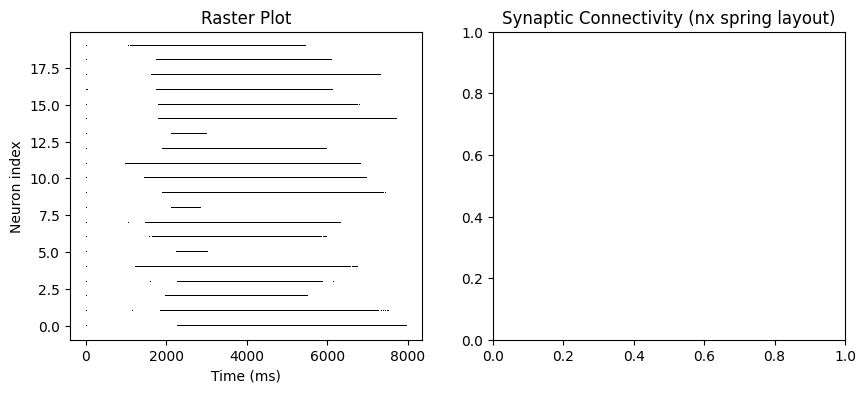

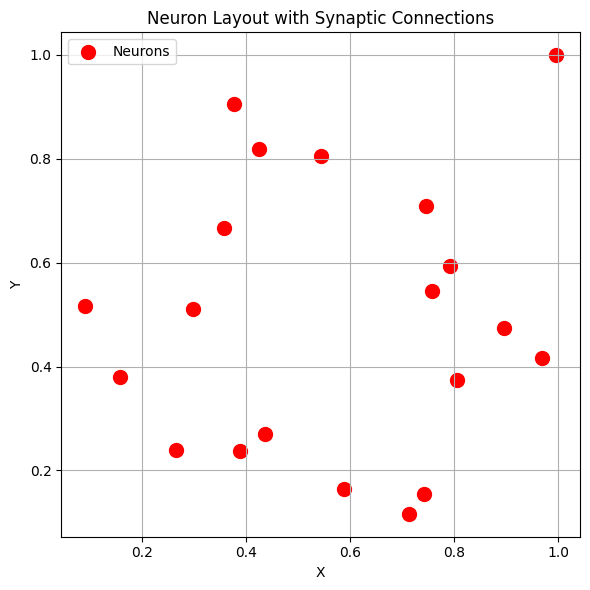

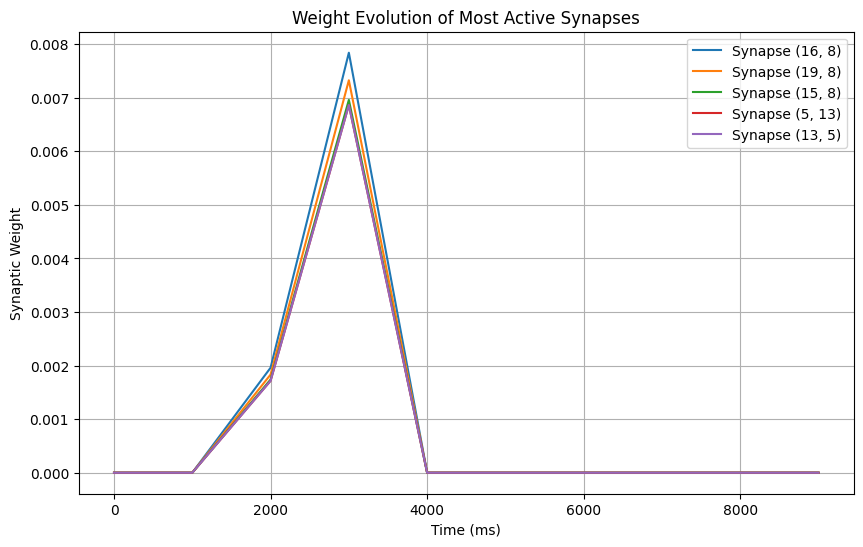

In [46]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
weight_trace = {}
times = []
target_rate=5*Hz
learning_rate = 0.01 #HS


neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    distance = np.abs(np.real(distance))
    arg = -distance**2 / (2 * sigma**2)
    arg = np.clip(arg, -700, 0)  # Avoid overflow in exp
    return np.exp(arg)


# HH model equations
eqs = '''
dv/dt = (I_total/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
I_total = I_syn + I_bg_dyn : amp
I_syn : amp
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
'''
#I_inj = -I_bg / (1 + exp((t - t_off) / (5*second))) : amp (shared)


# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 1.0*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
El = -65*mV
area = 20000*umetre**2
t_on = 100.0*ms
t_off = 3000*ms
I_bg = -1.0*nA

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='heun')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_syn = 0

# Poisson input to N_stim random neurons
P_input = PoissonGroup(N, rates=5*Hz)  # low rate
S_input = Synapses(P_input, neurons, on_pre='I_syn_post += 0.5*nA')
S_input.connect(j='i')  # each Poisson neuron connects to one matching neuron

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_syn_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w=0.00

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    if defaultclock.t == 0*ms:
        return  
    
    rates = spikes.count / defaultclock.t
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")

    for post in range(N):
        rate_post = rates[post]
        pos_post = neuron_positions[post]

        for pre in range(N):
            if pre == post:
                continue

            dist = np.linalg.norm(neuron_positions[pre] - pos_post)
            dist = float(np.abs(np.real(dist)))
            if dist > 0.5:
                continue

            scale = gaussian_weight(dist)

            if np.isnan(scale):
                print(f"NaN in scale: dist={dist}")

            delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)

            if np.isnan(delta):
                print(f"NaN in delta: rate_post={rate_post}, target_rate={target_rate}")

            new_weight = S_rec.w[pre, post] + delta * learning_rate * scale
            new_weight = clip(new_weight, 0, 1.0)

            if np.isnan(new_weight):
                print(f"NaN in new weight for synapse ({pre}->{post}): "
                      f"w={S_rec.w[pre, post]}, delta={delta}, scale={scale}")
            
            S_rec.w[pre, post] = new_weight

    print(f"Weight range: min={np.min(S_rec.w[:])}, max={np.max(S_rec.w[:])}")



# @network_operation(dt=2500*ms)
# def weight_decay():
#     decay_rate = 0.001  # percent decay per second
#     S_rec.w[:] *= (1 - decay_rate)
#     prune_threshold = 0.0001
#     S_rec.w[S_rec.w < prune_threshold] = 0
#     num_pruned = np.sum(S_rec.w[:] < prune_threshold)
#     print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)



print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")



# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()




[Text(0, 0.5, 'Neuron index'), Text(0.5, 0, 'time (ms)')]

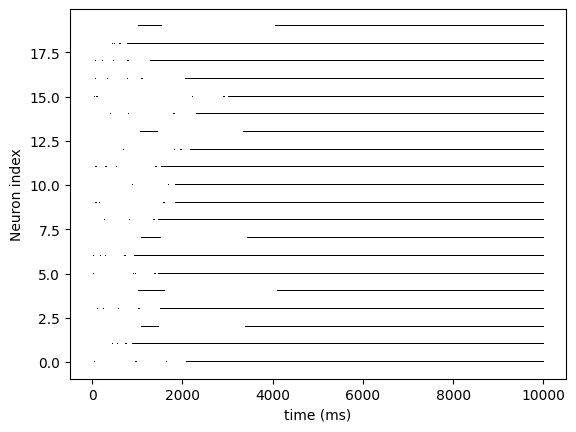

In [15]:
fig, ax = plt.subplots()
ax.plot(spikes.t/ms, spikes.i, ',k')
ax.set(ylabel='Neuron index', xlabel='time (ms)')

In [ ]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
weight_trace = {}
times = []
target_rate=5*Hz
learning_rate = 0.01 #HS


neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    distance = np.abs(np.real(distance))
    arg = -distance**2 / (2 * sigma**2)
    arg = np.clip(arg, -700, 0)  # Avoid overflow in exp
    return np.exp(arg)


#   Conductance based model equations
eqs = '''
dVm/dt = -(gNa*m**3*h*(Vm - ENa) + gK*n**4*(Vm - EK) + gleak*(Vm - Eleak) - I_inj) / C : volt
I_total = I_syn + I_bg_dyn : amp
I_syn : amp
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)        
dm/dt = alpham*(1-m) - betam*m : 1
dn/dt = alphan*(1-n) - betan*n : 1
dh/dt = alphah*(1-h) - betah*h : 1

alpham = (-0.32/mV) * (Vm - VT - 13.*mV) / (exp((-(Vm - VT - 13.*mV))/(4.*mV)) - 1)/ms : Hz
betam = (0.28/mV) * (Vm - VT - 40.*mV) / (exp((Vm - VT - 40.*mV)/(5.*mV)) - 1)/ms : Hz

alphah = 0.128 * exp(-(Vm - VT - 17.*mV) / (18.*mV))/ms : Hz
betah = 4/(1 + exp((-(Vm - VT - 40.*mV)) / (5.*mV)))/ms : Hz

alphan = (-0.032/mV) * (Vm - VT - 15.*mV) / (exp((-(Vm - VT - 15.*mV)) / (5.*mV)) - 1)/ms : Hz
betan = 0.5*exp(-(Vm - VT - 10.*mV) / (40.*mV))/ms : Hz
# The parameters to fit
gNa : siemens (constant)
gK : siemens (constant)
'''
#I_inj = -I_bg / (1 + exp((t - t_off) / (5*second))) : amp (shared)


# Constants
gleak = 10*nS
Eleak = -70*mV
VT = -60.0*mV
C = 200*pF
ENa = 53*mV
EK = -107*mV
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 1.0*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
El = -65*mV
area = 20000*umetre**2
t_on = 100.0*ms
t_off = 3000*ms
I_bg = -1.0*nA

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='heun')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_syn = 0

# Poisson input to N_stim random neurons
P_input = PoissonGroup(N, rates=5*Hz)  # low rate
S_input = Synapses(P_input, neurons, on_pre='I_syn_post += 0.5*nA')
S_input.connect(j='i')  # each Poisson neuron connects to one matching neuron

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_syn_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w=0.00

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    if defaultclock.t == 0*ms:
        return  
    
    rates = spikes.count / defaultclock.t
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")

    for post in range(N):
        rate_post = rates[post]
        pos_post = neuron_positions[post]

        for pre in range(N):
            if pre == post:
                continue

            dist = np.linalg.norm(neuron_positions[pre] - pos_post)
            dist = float(np.abs(np.real(dist)))
            if dist > 0.5:
                continue

            scale = gaussian_weight(dist)

            if np.isnan(scale):
                print(f"NaN in scale: dist={dist}")

            delta = np.clip((target_rate - rate_post) / target_rate, -1.0, 1.0)

            if np.isnan(delta):
                print(f"NaN in delta: rate_post={rate_post}, target_rate={target_rate}")

            new_weight = S_rec.w[pre, post] + delta * learning_rate * scale
            new_weight = clip(new_weight, 0, 1.0)

            if np.isnan(new_weight):
                print(f"NaN in new weight for synapse ({pre}->{post}): "
                      f"w={S_rec.w[pre, post]}, delta={delta}, scale={scale}")
            
            S_rec.w[pre, post] = new_weight

    print(f"Weight range: min={np.min(S_rec.w[:])}, max={np.max(S_rec.w[:])}")



# @network_operation(dt=2500*ms)
# def weight_decay():
#     decay_rate = 0.001  # percent decay per second
#     S_rec.w[:] *= (1 - decay_rate)
#     prune_threshold = 0.0001
#     S_rec.w[S_rec.w < prune_threshold] = 0
#     num_pruned = np.sum(S_rec.w[:] < prune_threshold)
#     print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)



print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")



# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()


